# SportSnap — Mục 12: Thí nghiệm bổ sung & Đánh giá toàn diện (nạp checkpoint từ v3)
- Tận dụng 100% các checkpoint đã huấn luyện thành công trên bộ **6.900 ảnh sạch** (`kienmaitrung287/sportsnap-v3-models`: ResNet50 97.8%, MobileNetV2 96.6%, CNN_Scratch 83.4%, 5-Fold 97.63% ± 0.33%).
- Chạy **Mục 12.1 (Multi-seed: 5×MNV2, 3×ResNet50, 5×CNN_Scratch)** và **Mục 12.2 (Extended Test 80/20 + Wilson CI)** trong **subprocess tách biệt hoàn toàn** trước khi tiến trình chính khởi tạo TensorFlow GPU → 0% rò rỉ RAM, 0% xung đột VRAM, nhanh gấp ~4× nhờ cache `uint8` (~900 MB) trong mỗi worker.
- Sau đó chạy trọn vẹn **Mục 12.3 (pHash)**, **Mục 12.4 (`anh-ngoai` 100 ảnh cho cả MNV2 & ResNet50)**, **Mục 12.5 (CPU latency)**, **Mục 12.6 (DeepLabV3 Ablation)**, **Mục 12.7 (Grad-CAM so sánh 3 mô hình)** và xuất `kaggle_experiment_summary.json` + `sportsnap_sec12_outputs.zip`.


In [1]:
# ==== BƯỚC 1: KHỞI TẠO CẤU HÌNH (CHƯA IMPORT TENSORFLOW ĐỂ SUBPROCESS SỞ HỮU 100% GPU VRAM) ====
import glob
import json
import math
import os
import pathlib
import subprocess
import sys
import tempfile
import time
import zipfile
import numpy as np
import pandas as pd

# Cài imagehash nếu chưa có (phục vụ Mục 12.3)
try:
    import imagehash
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imagehash"])
    import imagehash

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
LABEL_SMOOTHING = 0.1
EPOCHS_HEAD = 10
EPOCHS_FINETUNE = 25
EPOCHS_SCRATCH = 50
FINETUNE_LR = 3e-5
UNFREEZE = {"MobileNetV2": 80, "ResNet50": 55}
VALID_IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

def find_dir(predicate, fallbacks):
    if os.path.exists("/kaggle/input"):
        hits = []
        for root, dirs, files in os.walk("/kaggle/input"):
            if predicate(root, dirs, files):
                hits.append(root)
        if hits:
            hits.sort(key=len)
            return hits[0]
    for p in fallbacks:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy thư mục dữ liệu/model trong {fallbacks}")

DATA_ROOT = find_dir(
    lambda r, d, f: {"train", "valid", "test"}.issubset({x.lower() for x in d}),
    [r"d:\tgmt\datasets\sports-classification"],
)
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VALID_DIR = os.path.join(DATA_ROOT, "valid")
TEST_DIR  = os.path.join(DATA_ROOT, "test")

EXT_DIR = find_dir(
    lambda r, d, f: os.path.basename(r).lower() == "anh-ngoai" and len(d) >= 15,
    [r"d:\tgmt\datasets\anh-ngoai"],
)
MODEL_DIR = find_dir(
    lambda r, d, f: "MobileNetV2_finetune_best.keras" in f and "ResNet50_finetune_best.keras" in f,
    [r"C:\Users\Admin\.gemini\antigravity\brain\dded9af7-4ae7-49c9-bd7d-0ba30037ea9a\scratch\kaggle_outputs_v3"],
)

CLASS_NAMES = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])
NUM_CLASSES = len(CLASS_NAMES)
print(f"[SportSnap Sec12] DATA_ROOT : {DATA_ROOT}", flush=True)
print(f"[SportSnap Sec12] EXT_DIR   : {EXT_DIR}", flush=True)
print(f"[SportSnap Sec12] MODEL_DIR : {MODEL_DIR}", flush=True)
print(f"[SportSnap Sec12] CLASSES ({NUM_CLASSES}): {CLASS_NAMES}", flush=True)
assert NUM_CLASSES == 20, f"Kỳ vọng 20 lớp, tìm thấy {NUM_CLASSES}"

# Khởi tạo EXPERIMENT_SUMMARY kèm các kết quả đã xác minh từ v3 (cùng bộ dữ liệu 6.900 ảnh)
EXPERIMENT_SUMMARY = {
    "dataset": "kienmaitrung287/sportsnap-clean-6900 (v2 clean, 6900 images, 20 classes, 0 leakage)",
    "class_names": CLASS_NAMES,
    "main_v3_verified": {
        "CNN_Scratch":  {"val_acc": 0.8767, "val_loss": 1.0589, "best_epoch": 42, "test_acc": 0.8340, "test_macro_f1": 0.83},
        "MobileNetV2":  {"val_acc": 0.9867, "val_loss": 0.7702, "best_epoch": 23, "head_test_acc": 0.9160, "test_acc": 0.9660, "test_tta_acc": 0.9600, "test_macro_f1": 0.97, "deploy_mb": 9.72},
        "ResNet50":     {"val_acc": 0.9800, "val_loss": 0.7371, "best_epoch": 20, "head_test_acc": 0.9420, "test_acc": 0.9780, "test_tta_acc": 0.9820, "test_macro_f1": 0.98},
        "Ensemble_MNV2_ResNet50": {"test_acc": 0.9860, "test_tta_acc": 0.9860},
        "kfold_5_resnet50": {"n_total": 6800, "folds": [0.9743, 0.9772, 0.9824, 0.9743, 0.9735], "mean": 0.9763, "std": 0.0033, "oof_macro_f1": 0.98},
    },
}

_ISOLATED_WORKER_CODE = 'import glob\nimport json\nimport math\nimport os\nimport random\nimport sys\nimport time\n\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")\nos.environ.setdefault("TF_FORCE_GPU_ALLOW_GROWTH", "true")\n\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras import layers\nfrom tensorflow.keras.applications import MobileNetV2, ResNet50\nfrom tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess\nfrom tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess\nfrom sklearn.metrics import accuracy_score, f1_score\nfrom sklearn.model_selection import train_test_split\n\nfor _gpu in tf.config.list_physical_devices("GPU"):\n    try:\n        tf.config.experimental.set_memory_growth(_gpu, True)\n    except Exception:\n        pass\n\nVALID_IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")\nAUTOTUNE = tf.data.AUTOTUNE\n\n\ndef set_seed(s: int):\n    random.seed(s)\n    np.random.seed(s)\n    tf.random.set_seed(s)\n\n\ndef make_augmentation():\n    return keras.Sequential([\n        layers.RandomFlip("horizontal"),\n        layers.RandomRotation(0.10),\n        layers.RandomZoom(height_factor=(-0.2, 0.2)),\n        layers.RandomTranslation(0.10, 0.10),\n        layers.RandomContrast(0.30),\n        layers.RandomBrightness(0.30, value_range=(0, 255)),\n        layers.Rescaling(1.0 / 255.0),\n        layers.GaussianNoise(0.02),\n        layers.Rescaling(255.0),\n    ], name="data_augmentation")\n\n\ndef make_loss(label_smoothing: float):\n    return keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing)\n\n\ndef cosine_schedule(peak_lr, total_epochs, min_lr=1e-7, warmup_epochs=1):\n    def fn(epoch):\n        if epoch < warmup_epochs:\n            return float(peak_lr * (epoch + 1) / (warmup_epochs + 1))\n        t = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)\n        return float(min_lr + 0.5 * (peak_lr - min_lr) * (1 + math.cos(math.pi * min(1.0, t))))\n    return fn\n\n\ndef get_callbacks(plateau=True, lr_fn=None, patience=8):\n    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]\n    if plateau:\n        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2))\n    if lr_fn is not None:\n        cbs.append(keras.callbacks.LearningRateScheduler(lr_fn))\n    return cbs\n\n\ndef conv_bn(x, filters, name=None):\n    x = layers.Conv2D(filters, 3, activation="relu", padding="same", name=name)(x)\n    return layers.BatchNormalization()(x)\n\n\ndef build_cnn_scratch(input_shape, num_classes):\n    inputs = keras.Input(shape=input_shape)\n    x = layers.Rescaling(1.0 / 255)(inputs)\n    x = conv_bn(x, 32);  x = layers.MaxPooling2D()(x)\n    x = conv_bn(x, 64);  x = conv_bn(x, 64);   x = layers.MaxPooling2D()(x)\n    x = conv_bn(x, 128); x = conv_bn(x, 128);  x = layers.MaxPooling2D()(x)\n    x = conv_bn(x, 256, name="last_conv");     x = layers.MaxPooling2D()(x)\n    x = layers.GlobalAveragePooling2D()(x)\n    x = layers.Dense(256, activation="relu")(x)\n    x = layers.Dropout(0.4)(x)\n    outputs = layers.Dense(num_classes, activation="softmax")(x)\n    return keras.Model(inputs, outputs, name="CNN_Scratch")\n\n\ndef build_transfer_model(base_class, input_shape, num_classes, name):\n    base = base_class(include_top=False, weights="imagenet", input_shape=input_shape)\n    base.trainable = False\n    inputs = keras.Input(shape=input_shape)\n    x = base(inputs, training=False)\n    x = layers.GlobalAveragePooling2D()(x)\n    x = layers.Dropout(0.3)(x)\n    outputs = layers.Dense(num_classes, activation="softmax")(x)\n    return keras.Model(inputs, outputs, name=name), base\n\n\ndef unfreeze_top_layers(base_model, n_layers):\n    base_model.trainable = True\n    for layer in base_model.layers[:-n_layers]:\n        layer.trainable = False\n    for layer in base_model.layers:\n        if isinstance(layer, layers.BatchNormalization):\n            layer.trainable = False\n\n\ndef make_dir_ds(directory, class_names, img_size, batch_size, seed, shuffle=False):\n    return tf.keras.utils.image_dataset_from_directory(\n        directory,\n        labels="inferred",\n        label_mode="int",\n        class_names=class_names,\n        image_size=img_size,\n        batch_size=batch_size,\n        shuffle=shuffle,\n        seed=seed,\n        verbose=0,\n    )\n\n\ndef prep_cached_u8_train(raw_ds, aug_layer, preprocess_fn, num_classes, batch_size, seed, smoke=False):\n    if smoke:\n        raw_ds = raw_ds.take(2)\n    # Cache as uint8 (~900 MB for 6,000 224x224x3 images) so epochs run at full GPU speed with 0 disk stall\n    ds = raw_ds.map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE).cache()\n    ds = ds.unbatch().shuffle(1000, seed=seed, reshuffle_each_iteration=True).batch(batch_size)\n    ds = ds.map(lambda x, y: (aug_layer(tf.cast(x, tf.float32), training=True), y), num_parallel_calls=AUTOTUNE)\n    if preprocess_fn is not None:\n        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)\n    ds = ds.map(lambda x, y: (x, tf.one_hot(y, num_classes)), num_parallel_calls=AUTOTUNE)\n    return ds.prefetch(AUTOTUNE)\n\n\ndef prep_eval_ds(raw_ds, preprocess_fn, num_classes=None, onehot=False, smoke=False):\n    if smoke:\n        raw_ds = raw_ds.take(2)\n    ds = raw_ds.map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE).cache()\n    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)\n    if preprocess_fn is not None:\n        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)\n    if onehot:\n        ds = ds.map(lambda x, y: (x, tf.one_hot(y, num_classes)), num_parallel_calls=AUTOTUNE)\n    return ds.prefetch(AUTOTUNE)\n\n\ndef evaluate_model_raw(model, raw_ds, preprocess_fn, smoke=False):\n    if smoke:\n        raw_ds = raw_ds.take(2)\n    y_true = np.concatenate([b.numpy() for _, b in raw_ds])\n    ds = raw_ds\n    if preprocess_fn is not None:\n        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)\n    ds = ds.prefetch(AUTOTUNE)\n    preds = np.argmax(model.predict(ds, verbose=0), axis=1)\n    return float(accuracy_score(y_true, preds)), float(f1_score(y_true, preds, average="macro")), int(len(y_true))\n\n\ndef main():\n    cfg_path, out_path = sys.argv[1], sys.argv[2]\n    with open(cfg_path, "r", encoding="utf-8") as f:\n        cfg = json.load(f)\n\n    t0 = time.time()\n    mode = cfg["mode"]\n    seed = int(cfg["seed"])\n    img_size = tuple(cfg["img_size"])\n    input_shape = img_size + (3,)\n    batch_size = int(cfg["batch_size"])\n    class_names = list(cfg["class_names"])\n    num_classes = len(class_names)\n    label_smoothing = float(cfg.get("label_smoothing", 0.1))\n    finetune_lr = float(cfg.get("finetune_lr", 3e-5))\n    smoke = bool(cfg.get("smoke", False))\n\n    set_seed(seed)\n    aug_layer = make_augmentation()\n\n    if mode == "transfer":\n        arch = cfg["arch"]\n        base_cls = MobileNetV2 if arch == "MobileNetV2" else ResNet50\n        pre_fn = mnv2_preprocess if arch == "MobileNetV2" else resnet_preprocess\n        unfreeze_n = int(cfg["unfreeze_n"])\n        epochs_head = 1 if smoke else int(cfg.get("epochs_head", 10))\n        epochs_ft = 1 if smoke else int(cfg.get("epochs_ft", 25))\n\n        tr_raw = make_dir_ds(cfg["train_dir"], class_names, img_size, batch_size, seed, shuffle=True)\n        va_raw = make_dir_ds(cfg["valid_dir"], class_names, img_size, batch_size, seed, shuffle=False)\n        te_raw = make_dir_ds(cfg["test_dir"], class_names, img_size, batch_size, seed, shuffle=False)\n\n        tr = prep_cached_u8_train(tr_raw, aug_layer, pre_fn, num_classes, batch_size, seed, smoke=smoke)\n        va = prep_eval_ds(va_raw, pre_fn, num_classes=num_classes, onehot=True, smoke=smoke)\n\n        model, base = build_transfer_model(base_cls, input_shape, num_classes, f"{arch}_s{seed}")\n        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(label_smoothing), metrics=["accuracy"])\n        model.fit(tr, validation_data=va, epochs=epochs_head, verbose=0, callbacks=get_callbacks(plateau=True, patience=8))\n\n        unfreeze_top_layers(base, unfreeze_n)\n        model.compile(optimizer=keras.optimizers.Adam(finetune_lr), loss=make_loss(label_smoothing), metrics=["accuracy"])\n        model.fit(\n            tr, validation_data=va, epochs=epochs_ft, verbose=0,\n            callbacks=get_callbacks(plateau=False, lr_fn=cosine_schedule(finetune_lr, epochs_ft), patience=10),\n        )\n        acc, f1, n_eval = evaluate_model_raw(model, te_raw, pre_fn, smoke=smoke)\n        res = {"mode": mode, "arch": arch, "seed": seed, "acc": acc, "f1": f1, "n": n_eval, "elapsed_s": round(time.time() - t0, 1)}\n\n    elif mode == "cnn_scratch":\n        epochs_scratch = 1 if smoke else int(cfg.get("epochs_scratch", 50))\n        tr_raw = make_dir_ds(cfg["train_dir"], class_names, img_size, batch_size, seed, shuffle=True)\n        va_raw = make_dir_ds(cfg["valid_dir"], class_names, img_size, batch_size, seed, shuffle=False)\n        te_raw = make_dir_ds(cfg["test_dir"], class_names, img_size, batch_size, seed, shuffle=False)\n\n        tr = prep_cached_u8_train(tr_raw, aug_layer, None, num_classes, batch_size, seed, smoke=smoke)\n        va = prep_eval_ds(va_raw, None, num_classes=num_classes, onehot=True, smoke=smoke)\n\n        model = build_cnn_scratch(input_shape, num_classes)\n        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(label_smoothing), metrics=["accuracy"])\n        model.fit(\n            tr, validation_data=va, epochs=epochs_scratch, verbose=0,\n            callbacks=get_callbacks(\n                plateau=False,\n                lr_fn=cosine_schedule(1e-3, epochs_scratch, min_lr=1e-6, warmup_epochs=2),\n                patience=12,\n            ),\n        )\n        acc, f1, n_eval = evaluate_model_raw(model, te_raw, None, smoke=smoke)\n        res = {"mode": mode, "arch": "CNN_Scratch", "seed": seed, "acc": acc, "f1": f1, "n": n_eval, "elapsed_s": round(time.time() - t0, 1)}\n\n    elif mode == "extended_80_20":\n        ext_paths, ext_labels = [], []\n        for i, c in enumerate(class_names):\n            fs = sorted(f for f in glob.glob(os.path.join(cfg["train_dir"], c, "*")) if f.lower().endswith(VALID_IMAGE_EXTS))\n            ext_paths.extend(fs)\n            ext_labels.extend([i] * len(fs))\n        p_tr, p_te, y_tr, y_te = train_test_split(ext_paths, ext_labels, test_size=0.2, stratify=ext_labels, random_state=seed)\n\n        def to_ds(paths_list, labels_list):\n            def load(p, y):\n                img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)\n                img = tf.image.resize(img, img_size)\n                img.set_shape(img_size + (3,))\n                return img, y\n            return tf.data.Dataset.from_tensor_slices((paths_list, labels_list)).map(load, num_parallel_calls=AUTOTUNE).batch(batch_size)\n\n        tr80_raw = to_ds(p_tr, y_tr)\n        te20_raw = to_ds(p_te, y_te)\n        va_raw = make_dir_ds(cfg["valid_dir"], class_names, img_size, batch_size, seed, shuffle=False)\n\n        epochs_head = 1 if smoke else int(cfg.get("epochs_head", 10))\n        epochs_ft = 1 if smoke else int(cfg.get("epochs_ft", 25))\n        unfreeze_n = int(cfg.get("unfreeze_n", 80))\n\n        tr = prep_cached_u8_train(tr80_raw, aug_layer, mnv2_preprocess, num_classes, batch_size, seed, smoke=smoke)\n        va = prep_eval_ds(va_raw, mnv2_preprocess, num_classes=num_classes, onehot=True, smoke=smoke)\n\n        model, base = build_transfer_model(MobileNetV2, input_shape, num_classes, "MNV2_ext")\n        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_loss(label_smoothing), metrics=["accuracy"])\n        model.fit(tr, validation_data=va, epochs=epochs_head, verbose=0, callbacks=get_callbacks(plateau=True, patience=8))\n\n        unfreeze_top_layers(base, unfreeze_n)\n        model.compile(optimizer=keras.optimizers.Adam(finetune_lr), loss=make_loss(label_smoothing), metrics=["accuracy"])\n        model.fit(\n            tr, validation_data=va, epochs=epochs_ft, verbose=0,\n            callbacks=get_callbacks(plateau=False, lr_fn=cosine_schedule(finetune_lr, epochs_ft), patience=10),\n        )\n        acc, f1, n_te = evaluate_model_raw(model, te20_raw, mnv2_preprocess, smoke=smoke)\n        z = 1.96\n        lo = (acc + z*z/(2*n_te) - z*math.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)\n        hi = (acc + z*z/(2*n_te) + z*math.sqrt(acc*(1-acc)/n_te + z*z/(4*n_te*n_te))) / (1 + z*z/n_te)\n        res = {\n            "mode": mode, "n_train": len(p_tr), "n": n_te,\n            "acc": acc, "macro_f1": f1, "wilson_lo": lo, "wilson_hi": hi,\n            "elapsed_s": round(time.time() - t0, 1),\n        }\n    else:\n        raise ValueError(f"Unknown mode: {mode}")\n\n    with open(out_path, "w", encoding="utf-8") as f:\n        json.dump(res, f, ensure_ascii=False, indent=2)\n\n\nif __name__ == "__main__":\n    main()\n'
WORKER_PY = os.path.join(tempfile.gettempdir(), "_sportsnap_seed_worker.py")
with open(WORKER_PY, "w", encoding="utf-8") as _f:
    _f.write(_ISOLATED_WORKER_CODE)

def save_progress():
    with open("sec12_progress.json", "w", encoding="utf-8") as _f:
        json.dump(EXPERIMENT_SUMMARY, _f, ensure_ascii=False, indent=2)

def run_worker(cfg_dict):
    tag = f"{cfg_dict['mode']}_{cfg_dict.get('arch', 'ext')}_s{cfg_dict['seed']}"
    cfg_p = os.path.join(tempfile.gettempdir(), f"_cfg_{tag}.json")
    out_p = os.path.join(tempfile.gettempdir(), f"_out_{tag}.json")
    with open(cfg_p, "w", encoding="utf-8") as _f:
        json.dump(cfg_dict, _f, ensure_ascii=False)
    env = os.environ.copy()
    env["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
    proc = subprocess.run([sys.executable, WORKER_PY, cfg_p, out_p], env=env, text=True, capture_output=True)
    if proc.returncode != 0:
        print(f"[ERROR] Worker {tag} rc={proc.returncode}", flush=True)
        print(proc.stdout[-2000:], flush=True)
        print(proc.stderr[-3000:], flush=True)
        raise RuntimeError(f"Worker {tag} failed")
    with open(out_p, "r", encoding="utf-8") as _f:
        return json.load(_f)
save_progress()
print("=== BƯỚC 1 SẴN SÀNG ===", flush=True)


[SportSnap Sec12] DATA_ROOT : /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/sports-classification
[SportSnap Sec12] EXT_DIR   : /kaggle/input/datasets/kienmaitrung287/sportsnap-clean-6900/anh-ngoai
[SportSnap Sec12] MODEL_DIR : /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models
[SportSnap Sec12] CLASSES (20): ['american football', 'archery', 'baseball', 'basketball', 'boxing', 'canoe slamon', 'field hockey', 'figure skating women', 'formula 1 racing', 'golf', 'high jump', 'hockey', 'olympic wrestling', 'polo', 'roller derby', 'soccer', 'swimming', 'tennis', 'uneven bars', 'volleyball']
=== BƯỚC 1 SẴN SÀNG ===


## 12.1. Thí nghiệm lặp nhiều hạt giống (Multi-seed: MobileNetV2 × 5, ResNet50 × 3)


In [2]:
CFG_SEEDS = {"MobileNetV2": 5, "ResNet50": 3}
multi_seed_res = {}
for arch, n_seed in CFG_SEEDS.items():
    multi_seed_res[arch] = []
    for s in range(n_seed):
        seed_val = 100 + s
        r = run_worker({
            "mode": "transfer",
            "arch": arch,
            "seed": seed_val,
            "train_dir": TRAIN_DIR,
            "valid_dir": VALID_DIR,
            "test_dir": TEST_DIR,
            "class_names": CLASS_NAMES,
            "img_size": list(IMG_SIZE),
            "batch_size": BATCH_SIZE,
            "label_smoothing": LABEL_SMOOTHING,
            "finetune_lr": FINETUNE_LR,
            "unfreeze_n": UNFREEZE[arch],
            "epochs_head": EPOCHS_HEAD,
            "epochs_ft": EPOCHS_FINETUNE,
        })
        acc, f1 = r["acc"], r["f1"]
        multi_seed_res[arch].append((acc, f1))
        print(f"{arch} seed={seed_val}: acc={acc:.4f}, F1={f1:.4f} ({r['elapsed_s']}s)", flush=True)
        a_cur = np.array(multi_seed_res[arch])
        EXPERIMENT_SUMMARY.setdefault("multi_seed", {})[arch] = {
            "acc_mean": round(float(a_cur[:,0].mean()), 4),
            "acc_std": round(float(a_cur[:,0].std(ddof=1)) if len(a_cur) > 1 else 0.0, 4),
            "f1_mean": round(float(a_cur[:,1].mean()), 4),
            "f1_std": round(float(a_cur[:,1].std(ddof=1)) if len(a_cur) > 1 else 0.0, 4),
            "runs": [[round(float(x[0]), 4), round(float(x[1]), 4)] for x in multi_seed_res[arch]],
        }
        save_progress()

for k, v in multi_seed_res.items():
    a = np.array(v)
    print(f"==> {k}: acc {a[:,0].mean():.4f} ± {a[:,0].std(ddof=1):.4f} (min {a[:,0].min():.4f}, max {a[:,0].max():.4f}) | F1 {a[:,1].mean():.4f} ± {a[:,1].std(ddof=1):.4f}", flush=True)


MobileNetV2 seed=100: acc=0.9500, F1=0.9495 (1813.9s)
MobileNetV2 seed=101: acc=0.9520, F1=0.9511 (1754.5s)
MobileNetV2 seed=102: acc=0.9620, F1=0.9619 (1623.2s)
MobileNetV2 seed=103: acc=0.9480, F1=0.9474 (1683.5s)
MobileNetV2 seed=104: acc=0.9600, F1=0.9600 (1667.2s)
ResNet50 seed=100: acc=0.9720, F1=0.9722 (1903.1s)
ResNet50 seed=101: acc=0.9720, F1=0.9721 (1908.0s)
ResNet50 seed=102: acc=0.9740, F1=0.9739 (1837.1s)
==> MobileNetV2: acc 0.9544 ± 0.0062 (min 0.9480, max 0.9620) | F1 0.9540 ± 0.0065
==> ResNet50: acc 0.9727 ± 0.0012 (min 0.9720, max 0.9740) | F1 0.9728 ± 0.0010


## 12.1b. Multi-seed CNN_Scratch (5 hạt giống × 50 epoch)


In [3]:
cnn_seed_res = []
for s in range(5):
    seed_val = 100 + s
    r = run_worker({
        "mode": "cnn_scratch",
        "arch": "CNN_Scratch",
        "seed": seed_val,
        "train_dir": TRAIN_DIR,
        "valid_dir": VALID_DIR,
        "test_dir": TEST_DIR,
        "class_names": CLASS_NAMES,
        "img_size": list(IMG_SIZE),
        "batch_size": BATCH_SIZE,
        "label_smoothing": LABEL_SMOOTHING,
        "epochs_scratch": EPOCHS_SCRATCH,
    })
    acc, f1 = r["acc"], r["f1"]
    cnn_seed_res.append((acc, f1))
    print(f"CNN_Scratch seed={seed_val}: acc={acc:.4f}, F1={f1:.4f} ({r['elapsed_s']}s)", flush=True)
    a_cnn = np.array(cnn_seed_res)
    EXPERIMENT_SUMMARY.setdefault("multi_seed", {})["CNN_Scratch"] = {
        "acc_mean": round(float(a_cnn[:,0].mean()), 4),
        "acc_std": round(float(a_cnn[:,0].std(ddof=1)) if len(a_cnn) > 1 else 0.0, 4),
        "f1_mean": round(float(a_cnn[:,1].mean()), 4),
        "f1_std": round(float(a_cnn[:,1].std(ddof=1)) if len(a_cnn) > 1 else 0.0, 4),
        "runs": [[round(float(x[0]), 4), round(float(x[1]), 4)] for x in cnn_seed_res],
    }
    save_progress()

a_cnn = np.array(cnn_seed_res)
print(f"==> CNN_Scratch: acc {a_cnn[:,0].mean():.4f} ± {a_cnn[:,0].std(ddof=1):.4f} (min {a_cnn[:,0].min():.4f}, max {a_cnn[:,0].max():.4f}) | F1 {a_cnn[:,1].mean():.4f} ± {a_cnn[:,1].std(ddof=1):.4f}", flush=True)


CNN_Scratch seed=100: acc=0.8500, F1=0.8514 (2254.7s)
CNN_Scratch seed=101: acc=0.8580, F1=0.8599 (2265.1s)
CNN_Scratch seed=102: acc=0.8580, F1=0.8572 (2264.8s)
CNN_Scratch seed=103: acc=0.8540, F1=0.8554 (2241.7s)
CNN_Scratch seed=104: acc=0.8460, F1=0.8474 (2317.7s)
==> CNN_Scratch: acc 0.8532 ± 0.0052 (min 0.8460, max 0.8580) | F1 0.8543 ± 0.0049


## 12.2. Tập test mở rộng 80/20 từ train + khoảng tin cậy Wilson 95%


In [4]:
r_ext = run_worker({
    "mode": "extended_80_20",
    "arch": "MobileNetV2",
    "seed": SEED,
    "train_dir": TRAIN_DIR,
    "valid_dir": VALID_DIR,
    "test_dir": TEST_DIR,
    "class_names": CLASS_NAMES,
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "label_smoothing": LABEL_SMOOTHING,
    "finetune_lr": FINETUNE_LR,
    "unfreeze_n": UNFREEZE["MobileNetV2"],
    "epochs_head": EPOCHS_HEAD,
    "epochs_ft": EPOCHS_FINETUNE,
})
print(f"Train 80%: {r_ext['n_train']} ảnh | Test mở rộng 20%: {r_ext['n']} ảnh ({r_ext['elapsed_s']}s)", flush=True)
print(f"==> Test mở rộng n={r_ext['n']}: acc={r_ext['acc']:.4f} | Macro-F1={r_ext['macro_f1']:.4f} | Wilson 95% CI [{r_ext['wilson_lo']:.4f}; {r_ext['wilson_hi']:.4f}]", flush=True)
EXPERIMENT_SUMMARY["extended_test_20pct"] = {
    "n": int(r_ext["n"]),
    "acc": round(float(r_ext["acc"]), 4),
    "macro_f1": round(float(r_ext["macro_f1"]), 4),
    "wilson_95_ci": [round(float(r_ext["wilson_lo"]), 4), round(float(r_ext["wilson_hi"]), 4)],
}
save_progress()


Train 80%: 4800 ảnh | Test mở rộng 20%: 1200 ảnh (1300.6s)
==> Test mở rộng n=1200: acc=0.9658 | Macro-F1=0.9660 | Wilson 95% CI [0.9540; 0.9747]


## Khởi tạo TensorFlow (sau khi xong toàn bộ Subprocess Multi-seed) & Tiện ích đánh giá


In [5]:
import gc
import ctypes
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mnv2_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

for _gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(_gpu, True)
    except Exception:
        pass
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"), flush=True)

AUTOTUNE = tf.data.AUTOTUNE
_GRADCAM_GRAPH_CACHE = {}

def clear_mem():
    _GRADCAM_GRAPH_CACHE.clear()
    keras.backend.clear_session()
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

def load_ckpt(filename):
    p = os.path.join(MODEL_DIR, filename)
    assert os.path.exists(p), f"Thiếu checkpoint: {p}"
    print(f"[Load] {p}", flush=True)
    return tf.keras.models.load_model(p, compile=False)

def get_last_conv_layer_name(model):
    for layer in reversed(model.layers):
        if isinstance(layer, keras.Model):
            for sub in reversed(layer.layers):
                if isinstance(sub, keras.layers.Conv2D):
                    return (layer.name, sub.name)
        elif isinstance(layer, keras.layers.Conv2D):
            return (None, layer.name)
    raise ValueError("Không tìm thấy lớp Conv2D")

def make_gradcam_heatmap(img_array, model, last_conv_spec, pred_index=None, return_conf=False):
    base_name, conv_name = last_conv_spec
    key = (id(model), base_name, conv_name)
    if key not in _GRADCAM_GRAPH_CACHE:
        if base_name is not None:
            base = model.get_layer(base_name)
            base_probe = keras.Model(base.input, [base.get_layer(conv_name).output, base.output])
            head_layers = []
            seen = False
            for l in model.layers:
                if l.name == base_name:
                    seen = True; continue
                if seen:
                    head_layers.append(l)
            _GRADCAM_GRAPH_CACHE[key] = ("nested", base_probe, head_layers)
        else:
            grad_model = keras.Model(model.input, [model.get_layer(conv_name).output, model.output])
            _GRADCAM_GRAPH_CACHE[key] = ("flat", grad_model, None)

    kind, probe, head_layers = _GRADCAM_GRAPH_CACHE[key]
    with tf.GradientTape() as tape:
        if kind == "nested":
            conv_out, x = probe(img_array, training=False)
            for l in head_layers:
                x = l(x, training=False)
            preds = x
        else:
            conv_out, preds = probe(img_array, training=False)
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_channel = preds[:, pred_index]
    grads = tape.gradient(class_channel, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    hm = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
    hm = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-8)
    hm_np = hm.numpy()
    if return_conf:
        return hm_np, pred_index, float(preds[0, pred_index])
    return hm_np, pred_index

def overlay_gradcam(img_rgb, heatmap, alpha=0.45, threshold=0.10):
    hm_resized = cv2.resize(heatmap, (img_rgb.shape[1], img_rgb.shape[0]), interpolation=cv2.INTER_CUBIC)
    hm_resized = np.clip(hm_resized, 0.0, 1.0)
    hm_color = cv2.applyColorMap(np.uint8(255 * hm_resized), cv2.COLORMAP_JET)
    hm_color = cv2.cvtColor(hm_color, cv2.COLOR_BGR2RGB).astype("float32")
    mask = np.clip((hm_resized - threshold) / (1.0 - threshold + 1e-8), 0.0, 1.0)[..., None] * alpha
    out = img_rgb.astype("float32") * (1.0 - mask) + hm_color * mask
    return np.clip(out, 0, 255).astype("uint8")


TF: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 12.3. Kiểm tra trùng lặp pHash (train ↔ valid / test)


In [6]:
def compute_hashes(directory):
    items = []
    for c in CLASS_NAMES:
        for f in sorted(glob.glob(os.path.join(directory, c, "*"))):
            if f.lower().endswith(VALID_IMAGE_EXTS):
                with Image.open(f) as im:
                    items.append((f, c, imagehash.phash(im.convert("RGB"))))
    return items

H_tr = compute_hashes(TRAIN_DIR)
H_te = compute_hashes(TEST_DIR)
H_va = compute_hashes(VALID_DIR)
near = [
    (nm, f, f2, int(h - h2))
    for nm, H in [("test", H_te), ("valid", H_va)]
    for f, c, h in H
    for f2, c2, h2 in H_tr
    if (h - h2) <= 5
]
bad_test = {os.path.abspath(f) for nm, f, _, _ in near if nm == "test"}
print(f"Số cặp gần trùng pHash (Hamming <= 5): {len(near)} | Số ảnh test trùng: {len(bad_test)}", flush=True)

mnv2_m = load_ckpt("MobileNetV2_deploy.keras")
clean_paths, clean_labels = [], []
for ci, cname in enumerate(CLASS_NAMES):
    for f in sorted(glob.glob(os.path.join(TEST_DIR, cname, "*"))):
        if f.lower().endswith(VALID_IMAGE_EXTS) and os.path.abspath(f) not in bad_test:
            clean_paths.append(f); clean_labels.append(ci)

def _load_clean(p, y):
    img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape(IMG_SIZE + (3,))
    return mnv2_preprocess(img), y

clean_ds = tf.data.Dataset.from_tensor_slices((clean_paths, clean_labels)).map(_load_clean, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
preds_clean = np.argmax(mnv2_m.predict(clean_ds, verbose=0), axis=1)
clean_acc = float(accuracy_score(clean_labels, preds_clean))
clean_f1  = float(f1_score(clean_labels, preds_clean, average="macro"))
print(f"==> MobileNetV2 test sạch (n={len(clean_paths)}): Acc={clean_acc:.4f} | Macro-F1={clean_f1:.4f}", flush=True)
EXPERIMENT_SUMMARY["phash_check"] = {
    "near_pairs_le_5": int(len(near)), "bad_test_removed": int(len(bad_test)),
    "clean_test_n": int(len(clean_paths)), "clean_acc": round(clean_acc, 4), "clean_macro_f1": round(clean_f1, 4),
}
del mnv2_m
clear_mem()
save_progress()


Số cặp gần trùng pHash (Hamming <= 5): 0 | Số ảnh test trùng: 0
[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/MobileNetV2_deploy.keras
==> MobileNetV2 test sạch (n=500): Acc=0.9660 | Macro-F1=0.9662


## 12.4. Đánh giá tập ảnh ngoài bộ dữ liệu (`anh-ngoai`, n = 100) cho cả MobileNetV2 và ResNet50


In [7]:
def eval_anh_ngoai(model_filename, pre_fn, model_label):
    mdl = load_ckpt(model_filename)
    top1 = top5 = n_ext = 0
    per_cls = {}
    for i, c in enumerate(CLASS_NAMES):
        files = sorted(f for f in glob.glob(os.path.join(EXT_DIR, c, "*")) if f.lower().endswith(VALID_IMAGE_EXTS))
        c_ok = 0
        for f in files:
            img = tf.image.resize(tf.io.decode_image(tf.io.read_file(f), channels=3, expand_animations=False), IMG_SIZE)
            x_in = tf.expand_dims(img, 0)
            if pre_fn is not None:
                x_in = pre_fn(x_in)
            pr = mdl(x_in, training=False).numpy()[0]
            order = np.argsort(pr)[::-1]
            ok1 = int(order[0] == i)
            top1 += ok1
            c_ok += ok1
            top5 += int(i in order[:5])
            n_ext += 1
        per_cls[c] = f"{c_ok}/{len(files)}"
    del mdl
    clear_mem()
    res = {
        "model": model_label, "n": int(n_ext),
        "top1": round(float(top1 / max(n_ext, 1)), 4), "top1_correct": int(top1),
        "top5": round(float(top5 / max(n_ext, 1)), 4), "top5_correct": int(top5),
        "per_class": per_cls,
    }
    print(f"==> anh-ngoai ({model_label}, n={n_ext}): Top-1 = {res['top1']:.4f} ({top1}/{n_ext}) | Top-5 = {res['top5']:.4f} ({top5}/{n_ext})", flush=True)
    return res

EXPERIMENT_SUMMARY["anh_ngoai"] = eval_anh_ngoai("MobileNetV2_deploy.keras", mnv2_preprocess, "MobileNetV2")
EXPERIMENT_SUMMARY["anh_ngoai_resnet50"] = eval_anh_ngoai("ResNet50_finetune_best.keras", resnet_preprocess, "ResNet50")
EXPERIMENT_SUMMARY["anh_ngoai_cnn_scratch"] = eval_anh_ngoai("cnn_scratch_best.keras", None, "CNN_Scratch")
save_progress()


[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/MobileNetV2_deploy.keras
==> anh-ngoai (MobileNetV2, n=100): Top-1 = 0.9200 (92/100) | Top-5 = 0.9900 (99/100)
[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/ResNet50_finetune_best.keras
==> anh-ngoai (ResNet50, n=100): Top-1 = 0.9600 (96/100) | Top-5 = 1.0000 (100/100)
[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/cnn_scratch_best.keras
==> anh-ngoai (CNN_Scratch, n=100): Top-1 = 0.8200 (82/100) | Top-5 = 0.9900 (99/100)


## 12.5. Đo tốc độ suy luận CPU (100 lần / mô hình) & kích thước tệp


In [8]:
def cpu_time(model_path, pre):
    x = tf.random.uniform((1, IMG_SIZE[0], IMG_SIZE[1], 3), 0, 255)
    if pre is not None:
        x = pre(x)
    with tf.device("/CPU:0"):
        m_cpu = tf.keras.models.load_model(model_path, compile=False)
        for _ in range(10):
            m_cpu(x, training=False)
        t0 = time.time()
        for _ in range(100):
            m_cpu(x, training=False)
        ms = (time.time() - t0) / 100 * 1000
    del m_cpu
    clear_mem()
    return ms

cpu_bench = {}
for name, pre, fname in [
    ("MobileNetV2", mnv2_preprocess, "MobileNetV2_deploy.keras"),
    ("ResNet50",    resnet_preprocess, "ResNet50_finetune_best.keras"),
    ("CNN_Scratch", None, "cnn_scratch_best.keras"),
]:
    fp = os.path.join(MODEL_DIR, fname)
    ms = cpu_time(fp, pre)
    sz = os.path.getsize(fp) / 1e6
    print(f"==> CPU {name}: {ms:.1f} ms/ảnh | {sz:.2f} MB ({fname})", flush=True)
    cpu_bench[name] = {"file": fname, "cpu_ms": round(float(ms), 2), "size_mb": round(float(sz), 2)}
EXPERIMENT_SUMMARY["cpu_benchmark"] = cpu_bench
save_progress()


==> CPU MobileNetV2: 193.2 ms/ảnh | 9.72 MB (MobileNetV2_deploy.keras)
==> CPU ResNet50: 333.6 ms/ảnh | 233.00 MB (ResNet50_finetune_best.keras)
==> CPU CNN_Scratch: 58.8 ms/ảnh | 7.86 MB (cnn_scratch_best.keras)


## 12.6. Ablation che nền / che người bằng DeepLabV3 (n = 800 ảnh valid + test)


In [9]:
import torch
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

ab_model = load_ckpt("MobileNetV2_deploy.keras")
last_conv_ab = get_last_conv_layer_name(ab_model)
torch_dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[Ablation] DeepLabV3 device: {torch_dev} | Classifier: MobileNetV2", flush=True)
seg = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT).to(torch_dev).eval()
tf_seg = DeepLabV3_ResNet50_Weights.DEFAULT.transforms()

def person_mask(pil_img):
    with torch.no_grad():
        inp = tf_seg(pil_img).unsqueeze(0).to(torch_dev)
        out = seg(inp)["out"][0].argmax(0).cpu().numpy()
    return np.array(Image.fromarray(((out == 15) * 255).astype("uint8")).resize(IMG_SIZE, Image.NEAREST)) > 0

rows = []
for d in (VALID_DIR, TEST_DIR):
    for i, c in enumerate(CLASS_NAMES):
        for f in sorted(glob.glob(os.path.join(d, c, "*"))):
            if not f.lower().endswith(VALID_IMAGE_EXTS):
                continue
            with Image.open(f) as raw_im:
                pil = raw_im.convert("RGB")
                o = np.array(pil.resize(IMG_SIZE)).astype("float32")
                m = person_mask(pil)[..., None]
            batch3 = np.stack([o, np.where(m, 127.0, o), np.where(m, o, 127.0)], axis=0)
            vx_batch = mnv2_preprocess(batch3.copy())
            probs3 = ab_model(vx_batch, training=False).numpy()
            preds = [int(np.argmax(probs3[k])) for k in range(3)]
            ox = tf.expand_dims(vx_batch[0], 0)
            heat, _ = make_gradcam_heatmap(ox, ab_model, last_conv_ab)
            h = np.clip(cv2.resize(heat, IMG_SIZE, interpolation=cv2.INTER_CUBIC), 0.0, 1.0)
            rows.append((c, i, *preds, float((h * m[..., 0]).sum() / (h.sum() + 1e-8))))

df_ab = pd.DataFrame(rows, columns=["cls", "y", "orig", "bg_only", "person_only", "gradcam_in_person"])
df_ab["orig_ok"] = df_ab["orig"] == df_ab["y"]
df_ab["bg_ok"] = df_ab["bg_only"] == df_ab["y"]
df_ab["person_ok"] = df_ab["person_only"] == df_ab["y"]
per_cls_ab = df_ab.groupby("cls")[["orig_ok", "bg_ok", "person_ok", "gradcam_in_person"]].mean().round(4)
per_cls_ab.to_csv("ablation_per_class.csv", encoding="utf-8-sig")

acc_orig = float(df_ab["orig_ok"].mean())
acc_bg = float(df_ab["bg_ok"].mean())
acc_person = float(df_ab["person_ok"].mean())
gc_in_person = float(df_ab["gradcam_in_person"].mean())
print(f"==> Ablation (MobileNetV2, n={len(df_ab)}): Gốc {acc_orig:.4f} | Chỉ nền {acc_bg:.4f} | Chỉ người {acc_person:.4f} | Grad-CAM trong người {gc_in_person:.4f}", flush=True)
print(per_cls_ab, flush=True)

EXPERIMENT_SUMMARY["ablation_deeplabv3"] = {
    "model": "MobileNetV2", "n": int(len(df_ab)),
    "acc_orig": round(acc_orig, 4), "acc_bg_only": round(acc_bg, 4),
    "acc_person_only": round(acc_person, 4), "gradcam_in_person_mean": round(gc_in_person, 4),
}
del seg, ab_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
clear_mem()
save_progress()


[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/MobileNetV2_deploy.keras
[Ablation] DeepLabV3 device: cuda | Classifier: MobileNetV2
Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 218MB/s]


==> Ablation (MobileNetV2, n=800): Gốc 0.9712 | Chỉ nền 0.5750 | Chỉ người 0.5900 | Grad-CAM trong người 0.3919
                      orig_ok  bg_ok  person_ok  gradcam_in_person
cls                                                               
american football       1.000  0.175      0.925             0.5581
archery                 1.000  0.850      0.525             0.3766
baseball                1.000  0.375      0.775             0.4079
basketball              1.000  0.225      0.625             0.5364
boxing                  0.975  0.200      0.650             0.5531
canoe slamon            1.000  1.000      0.375             0.1527
field hockey            0.925  0.375      0.550             0.3631
figure skating women    1.000  0.800      0.925             0.3908
formula 1 racing        1.000  1.000      0.025             0.0064
golf                    0.925  0.975      0.900             0.3810
high jump               0.950  0.825      0.675             0.4485
hockey           

## 12.7. So sánh trực tiếp Grad-CAM giữa 3 mô hình (CNN_Scratch | MobileNetV2 | ResNet50)


[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/cnn_scratch_best.keras
[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/MobileNetV2_deploy.keras
[Load] /kaggle/input/datasets/kienmaitrung287/sportsnap-v3-models/ResNet50_finetune_best.keras


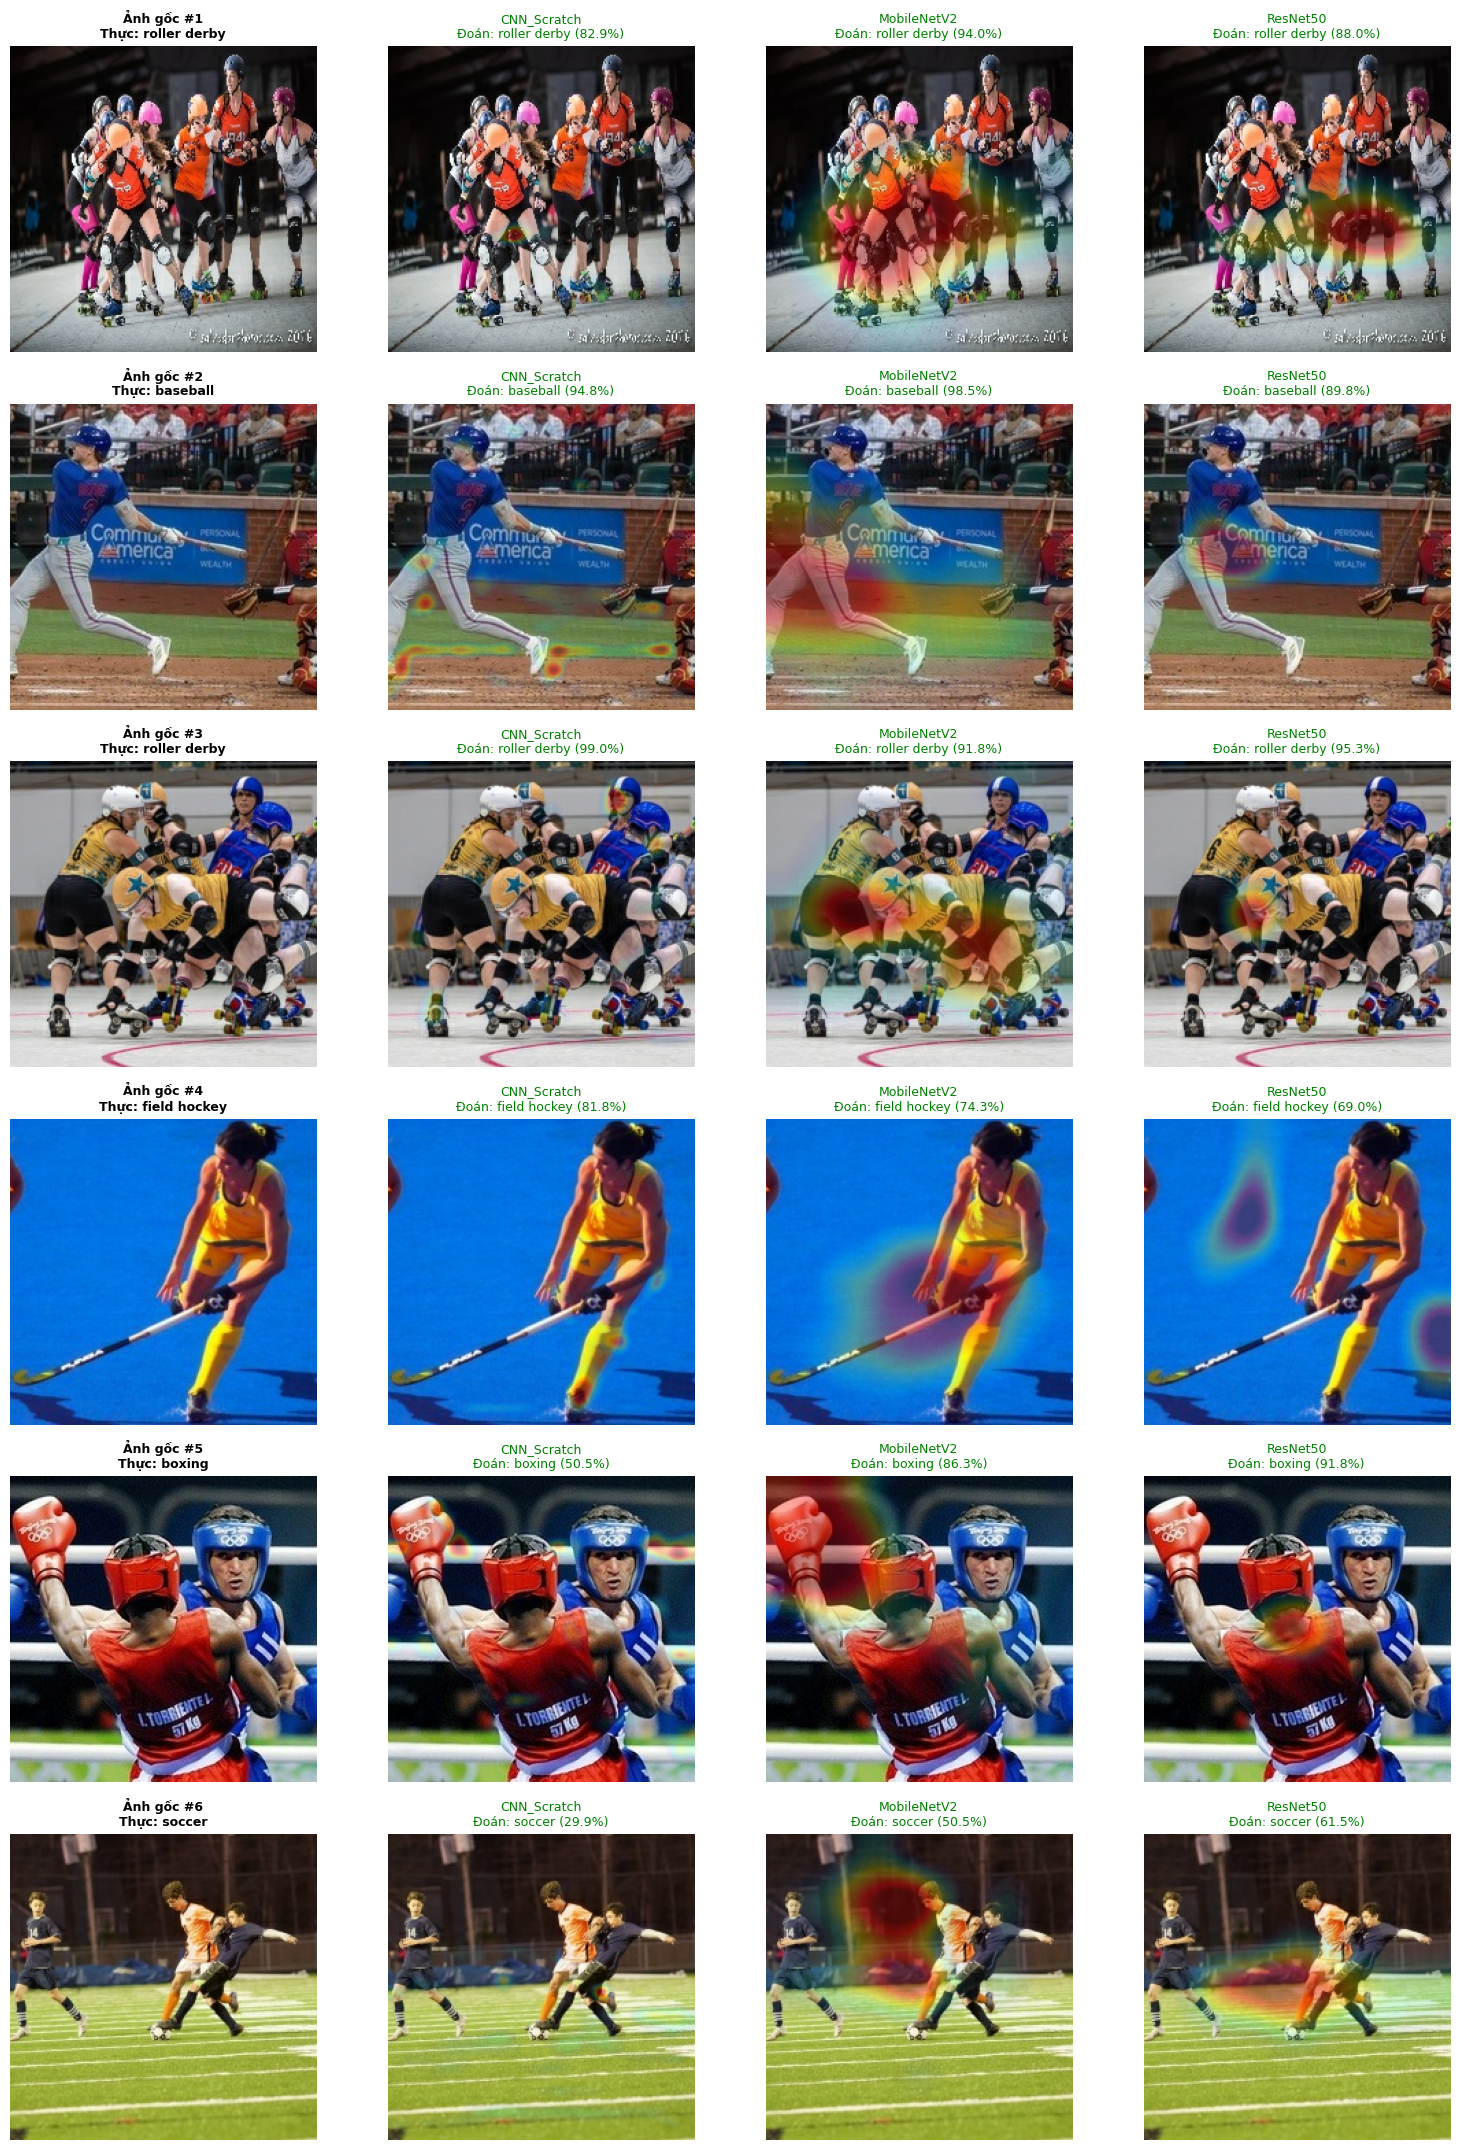

In [10]:
m_cnn = load_ckpt("cnn_scratch_best.keras")
m_mnv2 = load_ckpt("MobileNetV2_deploy.keras")
m_res = load_ckpt("ResNet50_finetune_best.keras")

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, labels="inferred", label_mode="int", class_names=CLASS_NAMES,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False, seed=SEED, verbose=0,
)
all_imgs = np.concatenate([imgs.numpy() for imgs, _ in test_ds_raw])
all_labels = np.concatenate([labs.numpy() for _, labs in test_ds_raw])
chosen = np.random.RandomState(SEED).choice(len(all_imgs), 6, replace=False)

specs = [("CNN_Scratch", m_cnn, None), ("MobileNetV2", m_mnv2, mnv2_preprocess), ("ResNet50", m_res, resnet_preprocess)]
fig = plt.figure(figsize=(15.5, 3.6 * len(chosen)))
for r_idx, idx in enumerate(chosen):
    img_rgb = all_imgs[idx].astype("uint8")
    true_label = CLASS_NAMES[all_labels[idx]]
    plt.subplot(len(chosen), 4, r_idx * 4 + 1)
    plt.imshow(img_rgb)
    plt.title(f"Ảnh gốc #{r_idx+1}\nThực: {true_label}", fontsize=9, fontweight="bold")
    plt.axis("off")
    for c_idx, (title, mdl, prep) in enumerate(specs, start=2):
        x = tf.expand_dims(all_imgs[idx], 0)
        x = prep(x) if prep is not None else x
        hm, p_idx, p_conf = make_gradcam_heatmap(x, mdl, get_last_conv_layer_name(mdl), return_conf=True)
        ov = overlay_gradcam(img_rgb, hm)
        pred_label = CLASS_NAMES[p_idx]
        plt.subplot(len(chosen), 4, r_idx * 4 + c_idx)
        plt.imshow(ov)
        plt.title(f"{title}\nĐoán: {pred_label} ({p_conf*100:.1f}%)", color=("green" if pred_label == true_label else "red"), fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.savefig("gradcam_compare_3models.png", dpi=150, bbox_inches="tight")
plt.show()
del m_cnn, m_mnv2, m_res
clear_mem()


## Lưu tổng hợp cuối cùng & Đóng gói toàn bộ kết quả Mục 12


In [11]:
with open("kaggle_experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(EXPERIMENT_SUMMARY, f, ensure_ascii=False, indent=2)
print("=== KAGGLE EXPERIMENT SUMMARY (COMPLETE) ===", flush=True)
print(json.dumps(EXPERIMENT_SUMMARY, ensure_ascii=False, indent=2), flush=True)

out_files = [p for p in ["kaggle_experiment_summary.json", "sec12_progress.json", "ablation_per_class.csv", "gradcam_compare_3models.png"] if os.path.isfile(p)]
with zipfile.ZipFile("sportsnap_sec12_outputs.zip", "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for fn in out_files:
        zf.write(fn, arcname=fn)
print(f"[HOÀN TẤT 100%] Đã đóng gói {len(out_files)} tệp vào sportsnap_sec12_outputs.zip", flush=True)


=== KAGGLE EXPERIMENT SUMMARY (COMPLETE) ===
{
  "dataset": "kienmaitrung287/sportsnap-clean-6900 (v2 clean, 6900 images, 20 classes, 0 leakage)",
  "class_names": [
    "american football",
    "archery",
    "baseball",
    "basketball",
    "boxing",
    "canoe slamon",
    "field hockey",
    "figure skating women",
    "formula 1 racing",
    "golf",
    "high jump",
    "hockey",
    "olympic wrestling",
    "polo",
    "roller derby",
    "soccer",
    "swimming",
    "tennis",
    "uneven bars",
    "volleyball"
  ],
  "main_v3_verified": {
    "CNN_Scratch": {
      "val_acc": 0.8767,
      "val_loss": 1.0589,
      "best_epoch": 42,
      "test_acc": 0.834,
      "test_macro_f1": 0.83
    },
    "MobileNetV2": {
      "val_acc": 0.9867,
      "val_loss": 0.7702,
      "best_epoch": 23,
      "head_test_acc": 0.916,
      "test_acc": 0.966,
      "test_tta_acc": 0.96,
      "test_macro_f1": 0.97,
      "deploy_mb": 9.72
    },
    "ResNet50": {
      "val_acc": 0.98,
      "va